# Adım 3b · MLP, standart PyTorch ile (nn.Module, mini-batch, Adam)

*3a'da ağı elle kurduk (val 2,39). Burada aynı fikri PyTorch'un hazır parçalarıyla yazıyoruz ve HistGB'nin test 2,42'sini geçmeye çalışıyoruz.*

**3a → 3b, ne değişiyor:**

| 3a (elle) | 3b (standart) | ne kazandırır |
|---|---|---|
| `W1, b1, W2, b2` tensörleri | `nn.Linear` katmanları, `nn.Module` sınıfı | katman eklemek tek satır; parametreleri PyTorch toplar |
| `p -= lr * p.grad`, `p.grad.zero_()` | `optimizer.step()`, `optimizer.zero_grad()` | aynı işi yapan hazır güncelleyici |
| düz gradient descent | **Adam** | her parametre için adım boyunu kendisi ayarlar, çok daha hızlı yakınsar |
| full-batch: epoch başına 1 adım | **mini-batch**: epoch başına ~49 adım (256'lık parçalar) | aynı epoch'ta çok daha fazla öğrenme; gürültü de genellemeye yardım eder |
| 1 gizli katman, 32 nöron | 2 gizli katman, 64'er nöron | daha fazla esneklik |

**Not (kararlar):** Cengo 2026-11-05 akşamı 3b'yi Pezo'ya bıraktı. Mimari (2×64), Adam (lr 0,001), batch 256 ve epoch sayısı Pezo'nun seçimi; gerekçeleri aşağıda, alternatifler 7. bölümde. Feature (2a'nın 8'i) ve loss (MSE) 3a'daki gibi Cengo'nun seçimi. **İtiraz edilecek yer varsa yarın değiştiririz.**

In [6]:
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

from ruzgar.data import load_aligned, split

aligned = load_aligned()
train, test = split(aligned)
train2, val = split(train, pd.Timestamp("2025-08-01", tz="UTC"))
MAE_HISTGB = 2.42  # 2b'nin test sonucu: geçmeye çalıştığımız çıta

## 1. Veri: 3a'nın aynısı

Tek fark: standardizasyon istatistiklerini parametre olarak alıyoruz. Önce train2'nin istatistiğiyle ayar seçeceğiz, en sonda bütün train'in istatistiğiyle yeniden eğiteceğiz.

In [7]:
def ozellikler(df):
    saat = df["time"].dt.hour
    ay = df["time"].dt.month
    yon = np.deg2rad(df["dir_deg_gfs"])
    X = pd.DataFrame(index=df.index)
    X["gfs"] = df["speed_kn_gfs"]
    X["saat_sin"] = np.sin(2 * np.pi * saat / 24)
    X["saat_cos"] = np.cos(2 * np.pi * saat / 24)
    X["ay_sin"] = np.sin(2 * np.pi * ay / 12)
    X["ay_cos"] = np.cos(2 * np.pi * ay / 12)
    X["u_ruzgar"] = df["speed_kn_gfs"] * np.sin(yon)
    X["v_ruzgar"] = df["speed_kn_gfs"] * np.cos(yon)
    X["hamle_gfs"] = df["gust_kn_gfs"]
    return X

def tensore(df, ort, std):
    x = torch.tensor(((ozellikler(df) - ort) / std).to_numpy(), dtype=torch.float32)
    y = torch.tensor(df["speed_kn_obs"].to_numpy(), dtype=torch.float32).unsqueeze(1)
    return x, y

ort2, std2 = ozellikler(train2).mean(), ozellikler(train2).std()
x_train2, y_train2 = tensore(train2, ort2, std2)
x_val, y_val = tensore(val, ort2, std2)
x_train2.shape

torch.Size([12423, 8])

## 2. Model: `nn.Module`

PyTorch'ta her model bir `nn.Module` sınıfıdır. İki şey yazarsın:
- `__init__`: katmanları oluştur. `nn.Linear(8, 64)` = 3a'daki `W1` (8×64) + `b1` (64), başlatması dahil.
- `forward`: veri nasıl akar. 3a'daki `ileri()` fonksiyonunun aynısı.

`super().__init__()` üst sınıfın (`nn.Module`) kurulumunu çalıştırır; PyTorch'un parametreleri takip edebilmesi için şart. (Python'da sınıf: `class` ile tanımlanan, kendi verisini ve fonksiyonlarını taşıyan şablon; `self` o nesnenin kendisi.)

In [8]:
class MLP(nn.Module):
    def __init__(self, giris=8, gizli=64):
        super().__init__()
        self.katman1 = nn.Linear(giris, gizli)   # 3a'daki W1, b1
        self.katman2 = nn.Linear(gizli, gizli)   # yeni: ikinci gizli katman
        self.cikis = nn.Linear(gizli, 1)         # 3a'daki W2, b2

    def forward(self, x):
        x = torch.relu(self.katman1(x))
        x = torch.relu(self.katman2(x))
        return self.cikis(x)

model = MLP()
print(model)
print("parametre sayısı:", sum(p.numel() for p in model.parameters()))

MLP(
  (katman1): Linear(in_features=8, out_features=64, bias=True)
  (katman2): Linear(in_features=64, out_features=64, bias=True)
  (cikis): Linear(in_features=64, out_features=1, bias=True)
)
parametre sayısı: 4801


8·64+64 + 64·64+64 + 64+1 = **4.801 parametre** (3a'da 321). İkinci katman, birinci katmanın bulduğu "kırık çizgileri" tekrar birleştirebilir; daha karmaşık desenler için.

`model(x)` yazınca PyTorch arka planda `model.forward(x)`'i çağırır.

## 3. Mini-batch: DataLoader

3a'da her adımda 12.423 satırın hepsine bakıp **bir** adım atıyorduk. Mini-batch'te veriyi karıştırıp 256'lık parçalara bölüyoruz ve her parçadan sonra bir adım atıyoruz: bir epoch = ~49 adım.

Neden işe yarıyor: 256 satır, bütün verinin gradyanını kabaca tahmin etmeye yetiyor; 49 kat daha sık adım atıyoruz. Tahmindeki gürültü de modelin keskin, ezber çukurlara oturmasını zorlaştırıyor.

`shuffle=True`: her epoch'ta parçalar farklı karışsın. Burada zaman sırasını bozmak sorun değil: train2'nin **içinde** karıştırıyoruz; val ve test hâlâ zamanca sonra ve hiç karışmıyor.

In [9]:
yukleyici = DataLoader(TensorDataset(x_train2, y_train2), batch_size=256, shuffle=True)
xb, yb = next(iter(yukleyici))   # ilk parçaya bakalım
print("bir parça:", xb.shape, yb.shape, "| epoch başına parça:", len(yukleyici))

bir parça: torch.Size([256, 8]) torch.Size([256, 1]) | epoch başına parça: 49


## 4. Eğitim fonksiyonu

Döngünün içi 3a'daki dört satırın standart hali:

| 3a | 3b |
|---|---|
| `tahmin = ileri(x)` | `tahmin = model(xb)` |
| `loss = ((tahmin - y) ** 2).mean()` | `loss = nn.functional.mse_loss(tahmin, yb)` |
| `loss.backward()` | `loss.backward()` (aynı) |
| `p -= lr * p.grad` ve `p.grad.zero_()` | `optimizer.step()` ve `optimizer.zero_grad()` |

**Adam (lr 0,001, Pezo'nun seçimi):** düz gradient descent her parametreye aynı `lr`'yi uygular. Adam her parametre için gradyanın geçmişini tutar: hep aynı yöne itilen parametrede adımı büyütür, zıplayanda küçültür (momentum + ölçekleme). 0,001 Adam'ın standart başlangıç değeri. Pratikte en yaygın optimizer.

`model.train()` / `model.eval()`: bazı katmanlar (dropout, batchnorm) eğitimde ve değerlendirmede farklı davranır. Bizde öyle katman yok ama alışkanlık olarak yazılır.

Fonksiyon her epoch sonunda train ve val MAE'sini kaydediyor; `eval_x` verilmezse yalnız eğitiyor.

In [15]:
def egit(x, y, epoch, lr=0.001, batch_size=256,eval_x=None, eval_y=None, tohum=0, gizli=64):
    torch.manual_seed(tohum)              # aynı başlangıç ve aynı karıştırma -> aynı sonuç
    model = MLP(gizli=gizli)
    optimizer = torch.optim.Adam(model.parameters(), lr)
    yukleyici = DataLoader(TensorDataset(x, y), batch_size, shuffle=True)
    gecmis = []
    for e in range(1, epoch + 1):
        model.train()
        for xb, yb in yukleyici:
            tahmin = model(xb)
            loss = nn.functional.mse_loss(tahmin, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        if eval_x is not None:
            model.eval()
            with torch.no_grad():
                gecmis.append({
                    "epoch": e,
                    "train": (model(x) - y).abs().mean().item(),
                    "val": (model(eval_x) - eval_y).abs().mean().item(),
                })
    return model, pd.DataFrame(gecmis)

model, g = egit(x_train2, y_train2, epoch=150, eval_x=x_val, eval_y=y_val)
g.iloc[[0, 9, 29, 49, 59, 99, 149]].round(3)

,epoch,train,val
0,1,5.498,5.873
9,10,2.512,2.522
29,30,2.343,2.459
49,50,2.300,2.343
59,60,2.283,2.400
99,100,2.235,2.398
149,150,2.176,2.401


In [20]:
# denenecek lr'ler
for lr in [0.0003, 0.001, 0.003, 0.01]:
    model_test, g_test = egit(x_train2, y_train2,lr=lr, epoch=100, eval_x=x_val, eval_y=y_val)
    yumusak = g_test["val"].rolling(5, center=True, min_periods=1).mean()
    print("lr:", lr, "en iyi val:", round(yumusak.min(), 3), "epoch:", yumusak.idxmin() + 1)
        # egit'i x_train2, y_train2 ile çağır; epoch=100, eval_x/eval_y val, lr=lr
    # dönen tablonun "val" sütununu 5 epoch ortalamasıyla yumuşat (6. bölümdeki satırın aynısı)
    # print: lr, en iyi val, hangi epoch'ta

lr: 0.0003 en iyi val: 2.398 epoch: 97
lr: 0.001 en iyi val: 2.35 epoch: 63
lr: 0.003 en iyi val: 2.355 epoch: 46
lr: 0.01 en iyi val: 2.341 epoch: 75


In [21]:
# denenecek batch'ler
for batch in [64, 128, 256, 512, 1024]:
    model_test, g_test = egit(x_train2, y_train2, batch_size=batch, lr=0.001, epoch=100, eval_x=x_val, eval_y=y_val)
    yumusak = g_test["val"].rolling(5, center=True, min_periods=1).mean()
    print("Batch Size:", batch, "en iyi val:", round(yumusak.min(), 3), "epoch:", yumusak.idxmin() + 1)
        # egit'i x_train2, y_train2 ile çağır; epoch=100, eval_x/eval_y val, lr=lr
    # dönen tablonun "val" sütununu 5 epoch ortalamasıyla yumuşat (6. bölümdeki satırın aynısı)
    # print: lr, en iyi val, hangi epoch'ta

Batch Size: 64 en iyi val: 2.354 epoch: 43
Batch Size: 128 en iyi val: 2.343 epoch: 44
Batch Size: 256 en iyi val: 2.35 epoch: 63
Batch Size: 512 en iyi val: 2.367 epoch: 90
Batch Size: 1024 en iyi val: 2.405 epoch: 91


3a'da 3000 adımda (epoch) val 2,39'a gelmiştik; burada ~50 epoch'ta (~2.500 adım) 2,34'e iniyoruz, üstelik 10. epoch'ta bile 2,52'deyiz. Adam ve mini-batch'in farkı bu.

## 5. Öğrenme eğrisi

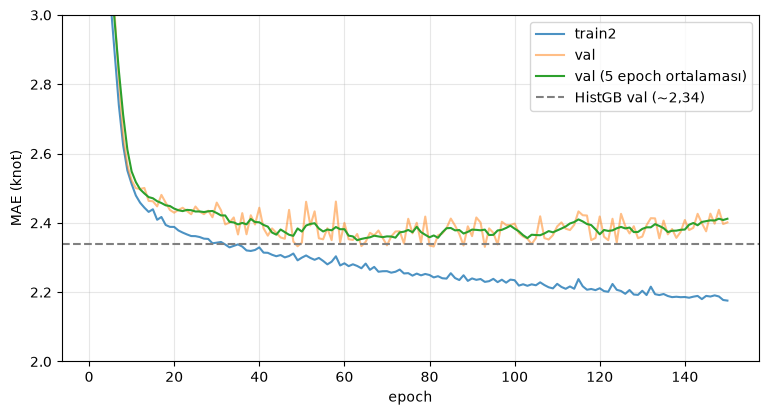

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(g["epoch"], g["train"], label="train2", alpha=0.8)
ax.plot(g["epoch"], g["val"], label="val", alpha=0.5)
ax.plot(g["epoch"], g["val"].rolling(5, center=True, min_periods=1).mean(), label="val (5 epoch ortalaması)")
ax.axhline(2.34, color="gray", linestyle="--", label="HistGB val (~2,34)")
ax.set_ylim(2.0, 3.0)
ax.set_xlabel("epoch")
ax.set_ylabel("MAE (knot)")
ax.legend()
ax.grid(alpha=0.3)

**Okuma (Pezo'nun ölçümü):**
- Val eğrisi epoch'tan epoch'a ±0,05 zıplıyor: mini-batch'in gürültüsü. O yüzden 5 epoch'luk ortalamaya bakıyoruz.
- Val ~50–100 epoch arasında **~2,33–2,35**'e iniyor: HistGB'nin val'iyle (~2,34) aynı seviye.
- Train düşmeye devam ediyor (150'de ~2,18), val yatay ya da hafif yukarı: 100'den sonra ezber başlıyor. Boosting'deki U eğrisinin aynısı, daha gürültülü hali.

## 6. Tohum (seed) etkisi

Ağın sonucu rastgele başlangıca ve karıştırmaya bağlı. Aynı ayarla 3 farklı tohum deneyelim: fark ne kadar? Bir modeli diğerinden "daha iyi" saymadan önce bu gürültüyü bilmek gerek.

In [12]:
for tohum in [0, 1, 2]:
    _, gt = egit(x_train2, y_train2, epoch=100, eval_x=x_val, eval_y=y_val, tohum=tohum)
    yumusak = gt["val"].rolling(5, center=True, min_periods=1).mean()
    print(f"tohum {tohum}: en iyi val (5 ep ort.) {yumusak.min():.3f}, epoch {int(yumusak.idxmin()) + 1};  60. epoch {yumusak.iloc[59]:.3f}")

tohum 0: en iyi val (5 ep ort.) 2.350, epoch 63;  60. epoch 2.382
tohum 1: en iyi val (5 ep ort.) 2.329, epoch 68;  60. epoch 2.339
tohum 2: en iyi val (5 ep ort.) 2.353, epoch 78;  60. epoch 2.368


Pezo'nun ölçümü: tohumlar arasında ~0,03 kn fark var, en iyi epoch 60 ile 100 arasında geziyor. Yani 2,33 ile 2,35 arasındaki farklar gürültü.

**Epoch seçimi (Pezo):** 60. 2b'deki gibi: val'in düz dibinin erken tarafı; daha geç seçmek ezbere yaklaştırır, kazancı da gürültü içinde.

## 7. Son ölçüm: bütün train'de eğit, testte bir kez

2b'yle aynı protokol: seçilen ayarla (2×64, Adam 0,001, batch 256, **60 epoch**) bütün train'de yeniden eğit, standardizasyonu da bütün train'den al, testte bir kez ölç. Tohum gürültüsünü görmek için 3 tohumun hepsini raporluyoruz (seçmiyoruz).

In [13]:
ort, std = ozellikler(train).mean(), ozellikler(train).std()
x_train, y_train = tensore(train, ort, std)
x_test, y_test = tensore(test, ort, std)

test_mae = []
for tohum in [0, 1, 2]:
    m, _ = egit(x_train, y_train, epoch=60, tohum=tohum)
    m.eval()
    with torch.no_grad():
        test_mae.append((m(x_test) - y_test).abs().mean().item())
mae_mlp = float(np.mean(test_mae))
print("test MAE (tohum 0, 1, 2):", [round(v, 3) for v in test_mae])
print(f"ortalama: {mae_mlp:.2f}   (HistGB: {MAE_HISTGB:.2f})")

test MAE (tohum 0, 1, 2): [2.445, 2.459, 2.466]
ortalama: 2.46   (HistGB: 2.42)


## 8. Sonuç

Pezo'nun ölçümü: MLP test **~2,45–2,47**, HistGB **2,42**. Yani **MLP boosting'i geçemedi**; val'de berabere, testte ~0,03–0,05 geride (tohum gürültüsü kadar bir fark).

Bu bir başarısızlık değil, bilinen bir sonuç: **küçük, tablo şeklindeki veride** (12–23 bin satır, 8 sütun) gradient boosting genelde sinir ağlarıyla aynı ya da daha iyi; üstelik daha hızlı ve ayarı daha az. Sinir ağları büyük veride ve yapılı veride (görüntü, metin, zaman dizisi) öne geçer. Proje B'de (Türkçe metin) tam tersini göreceğiz.

Burada kazandığımız şey: eğitim döngüsünün her parçasını (forward, loss, backward, optimizer, mini-batch, validation, seed gürültüsü) bilerek kullanmak. LSTM/transformer ve Proje B'deki fine-tune'un hepsi bu döngünün üstüne kurulu.

In [14]:
pd.DataFrame({
    "yöntem": ["ham GFS", "aylık düzeltme", "LR + elle feature (2a)", "HistGB, 125 ağaç (2b)", "MLP 2×64, Adam, 60 epoch (3b)"],
    "test MAE": [4.41, 3.65, 2.90, MAE_HISTGB, mae_mlp],
}).round(2)

,yöntem,test MAE
0,ham GFS,4.41
1,aylık düzeltme,3.65
2,LR + elle feature (2a),2.90
3,"HistGB, 125 ağaç (2b)",2.42
4,"MLP 2×64, Adam, 60 epoch (3b)",2.46


## 9. Yarın için seçenekler (Cengo karar verecek)

Pezo'nun 3b'de kendi seçtiği ve senin değiştirebileceğin şeyler:
- **Mimari:** 2×64 yerine 1×32 (3a'nınki; Adam 0,001 ile çok yavaş öğreniyor, 80 epoch'ta val 2,83), 2×128 (val ~2,32), 3×64 (val ~2,31–2,35). Fark tohum gürültüsü düzeyinde.
- **Ezberi azaltmak:** dropout ya da weight decay (ağırlıkları küçük tutma cezası).
- **Loss:** MSE yerine MAE (L1) ya da Huber; metriğimiz MAE.
- **Topluluk (ensemble):** 5 tohumun tahminlerinin ortalaması; tohum gürültüsünü azaltır, genelde küçük bir kazanç getirir. Ama seçimi val'de yapmalıyız; test'e artık bakmamalıyız.
- **Sıradaki büyük adım (3. adımın devamı):** geçmiş saatleri de gören bir model (LSTM ya da küçük transformer): GFS'in son 24 saatlik hatası yarını tahmin etmeye yardım eder mi?

**Alıştırma (iskelet seviyesi):** `MLP` sınıfına `gizli2` diye ikinci katmanın genişliğini ayrı veren bir parametre ekle ve 1×32 / 2×64 / 3×64'ü val'de karşılaştıran bir döngü yaz (2b'deki `sonuclar` kalıbı).